# RHG chiral superconductivity: supporting calculations

Supporting numerical module for **"Reading the chiral pairing state of
rhombohedral graphene from its thermal Hall conductance."**

Every calculation quoted in the manuscript that is not part of the DMRG
campaign is reproduced here, in one place, with the figures the paper uses.

| Part | Content | Manuscript item |
|---|---|---|
| 1 | Model definition (annular/disk Fermi sea, chiral gap textures, FHS Chern number) | Eqs. (24)-(25) |
| 2 | Four benchmark cases, $N_k=201$ | Table IV |
| 3 | Gap phase and magnitude with annular Fermi sheets | Fig. 9 |
| 4 | Converged vortex-crossing scan | Fig. 5 |
| 5 | FHS grid convergence: why $N_k=81$ misassigns one point | Sec. II D text |
| 6 | Nambu prefactor: reconciliation with Zeng-Wang-Niu | Sec. III C |
| 7 | Exact finite-$T$ thermal kernel $\mathcal{G}(x)$ and the tanh limit | Eqs. (21)-(23), Table I |

**Scope.** This is not a self-consistent solution of the Le Nir-Mitra-Kim
$\lambda_N$ gap equation. The finite-momentum vortices are inserted
explicitly as a controlled proxy for Berry-curvature-nucleated vortices.
The notebook therefore tests the *topological bookkeeping* that converts a
vortex configuration into $C_{\rm BdG}$; it does not by itself demonstrate
that the parent-band Berry curvature nucleates those vortices. The
manuscript states this scope in the same terms.

## 0. Setup

Single shared configuration: imports, plot style, output paths.

In [1]:
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from pathlib import Path
from scipy.special import spence
from scipy.integrate import quad
from scipy.optimize import brentq

mpl.rcParams.update({
    "font.family": "serif",
    "font.serif": ["Computer Modern Roman", "DejaVu Serif", "Times New Roman"],
    "mathtext.fontset": "cm",
    "font.size": 12,
    "axes.labelsize": 16,
    "axes.titlesize": 13,
    "legend.fontsize": 14,
    "xtick.labelsize": 12,
    "ytick.labelsize": 12,
    "axes.linewidth": 1.5,
    "xtick.direction": "in",
    "ytick.direction": "in",
    "xtick.top": True,
    "ytick.right": True,
    "figure.dpi": 140,
    "savefig.dpi": 300,
    "savefig.bbox": "tight",
})

OUTDIR = Path("RHG_even_chern_outputs")
FIGDIR = OUTDIR / "figures"
OUTDIR.mkdir(exist_ok=True)
FIGDIR.mkdir(exist_ok=True)
np.set_printoptions(precision=8, suppress=True)

# Global model parameters, used throughout.
PARAMS = dict(r_in=0.45, r_out=1.35, q=0.90, Delta0=0.50, chirality=-1)
NK_MAIN = 201        # production grid; see Part 5 for the convergence study

print("output directory:", OUTDIR.resolve())
print("model parameters:", PARAMS)

output directory: /home/claude/nbrun/RHG_even_chern_outputs
model parameters: {'r_in': 0.45, 'r_out': 1.35, 'q': 0.9, 'Delta0': 0.5, 'chirality': -1}


## 1. Model definition

Periodic Brillouin-zone regularization of the continuum annular problem,

$$\rho^2(k_x,k_y) = 4 - 2\cos k_x - 2\cos k_y \simeq k_x^2 + k_y^2 ,$$

with disk and annular dispersions

$$\xi_{\rm disk} = \rho^2 - r_{\rm out}^2 ,
\qquad
\xi_{\rm ann} = (\rho^2 - r_{\rm in}^2)(\rho^2 - r_{\rm out}^2) ,$$

so the annulus $r_{\rm in} < \rho < r_{\rm out}$ is the occupied region.
The minimal chiral texture and the finite-vortex texture are

$$\Delta_p = \Delta_0(\sin k_x + i\chi\sin k_y),$$

$$\Delta_{\rm ring} = \Delta_0(\sin k_x + i\chi\sin k_y)
[\sin k_x - \sin q + i\chi\sin k_y]
[\sin k_x + \sin q + i\chi\sin k_y].$$

The latter has one central vortex and a pair at $k_x = \pm q$, $k_y = 0$;
in the annular case the pair lies inside the occupied region when
$r_{\rm in} < 2\sin(q/2) < r_{\rm out}$.

Chern numbers use the gauge-invariant Fukui-Hatsugai-Suzuki (FHS)
construction. FHS is exact provided every plaquette flux satisfies
$|F_{\rm plaq}| < \pi$, so **every routine below returns
$\max|F_{\rm plaq}|$ alongside the Chern number** as a validity
certificate. This is what the manuscript reports.

In [2]:
def rho2_lattice(kx, ky):
    '''Periodic lattice regularization of k^2 near Gamma.'''
    return 4.0 - 2.0*np.cos(kx) - 2.0*np.cos(ky)


def xi_k(kx, ky, fs="annular", r_in=0.45, r_out=1.35):
    '''Normal-state dispersion relative to the chemical potential.'''
    r2 = rho2_lattice(kx, ky)
    if fs == "disk":
        return r2 - r_out**2
    if fs == "annular":
        return (r2 - r_in**2) * (r2 - r_out**2)
    raise ValueError("fs must be 'disk' or 'annular'")


def delta_k(kx, ky, pairing="minimal", q=0.90, Delta0=0.50, chirality=-1):
    '''Chiral gap texture.

    chirality = -1 gives positive C_BdG in the Nambu convention used below;
    flipping chirality reverses the sign of the Chern number.
    '''
    z = np.sin(kx) + 1j*chirality*np.sin(ky)
    if pairing == "minimal":
        return Delta0 * z
    if pairing == "finite_vortices":
        f_plus  = (np.sin(kx) - np.sin(q)) + 1j*chirality*np.sin(ky)
        f_minus = (np.sin(kx) + np.sin(q)) + 1j*chirality*np.sin(ky)
        return Delta0 * z * f_plus * f_minus
    raise ValueError("pairing must be 'minimal' or 'finite_vortices'")


def fhs_chern(Nk, fs="annular", pairing="minimal", params=None):
    '''Gauge-invariant FHS Chern number of the occupied BdG band.

    Returns (C_FHS, max|F_plaq|, min gap on the 2D grid).
    '''
    p = dict(PARAMS if params is None else params)
    ks = np.linspace(-np.pi, np.pi, Nk, endpoint=False)
    KX, KY = np.meshgrid(ks, ks, indexing="ij")
    XI = xi_k(KX, KY, fs=fs, r_in=p["r_in"], r_out=p["r_out"])
    DE = delta_k(KX, KY, pairing=pairing, q=p["q"],
                 Delta0=p["Delta0"], chirality=p["chirality"])
    E = np.sqrt(XI**2 + np.abs(DE)**2)

    # occupied (negative-energy) eigenvector of [[xi, D], [D*, -xi]]
    v0, v1 = DE, -XI - E
    n = np.sqrt(np.abs(v0)**2 + np.abs(v1)**2)
    bad = n < 1e-14
    v0 = np.where(bad, 1.0 + 0j, v0/np.where(bad, 1.0, n))
    v1 = np.where(bad, 0.0 + 0j, v1/np.where(bad, 1.0, n))
    vec = np.stack([v0, v1], axis=-1)

    ovx = np.sum(np.conj(vec)*np.roll(vec, -1, axis=0), axis=-1)
    ovy = np.sum(np.conj(vec)*np.roll(vec, -1, axis=1), axis=-1)
    Ux, Uy = ovx/np.abs(ovx), ovy/np.abs(ovy)
    F = np.angle(Ux*np.roll(Uy, -1, axis=0)/(np.roll(Ux, -1, axis=1)*Uy))
    return F.sum()/(2*np.pi), np.abs(F).max(), E.min()


def min_gap_ky0(q, params=None, npts=200001):
    '''True minimum BdG gap.

    All zeros of the finite-vortex gap lie on k_y = 0, which the periodic
    2D grid (odd N, endpoint=False) never samples. A dedicated fine 1D scan
    along that line therefore gives the true minimum; the 2D grid value is a
    sampling artefact.
    '''
    p = dict(PARAMS if params is None else params)
    kx = np.linspace(-np.pi, np.pi, npts)
    XI = xi_k(kx, 0.0, fs="annular", r_in=p["r_in"], r_out=p["r_out"])
    DE = delta_k(kx, 0.0, pairing="finite_vortices", q=q,
                 Delta0=p["Delta0"], chirality=p["chirality"])
    return np.sqrt(XI**2 + np.abs(DE)**2).min()


def analytic_vortex_charge(fs="annular", pairing="minimal", q=0.90,
                           r_in=0.45, r_out=1.35, chirality=-1, **kw):
    '''Occupied-vortex charge: C_BdG = sum of windings enclosed by the
    occupied Fermi sea. This is the rule the FHS calculation tests.'''
    s = -chirality
    r = 2*np.sin(q/2)
    if fs == "disk":
        Q = s                                   # central vortex occupied
        if pairing == "finite_vortices" and r < r_out:
            Q += 2*s
        return Q
    Q = 0                                       # central vortex excluded
    if pairing == "finite_vortices" and r_in < r < r_out:
        Q += 2*s
    return Q

## 2. Four benchmark cases (manuscript Table IV)

| Fermi sea | Gap texture | Expected |
|---|---|---|
| disk | minimal, central vortex only | $C_{\rm BdG} = 1$ |
| annulus | minimal, central vortex excluded | $C_{\rm BdG} = 0$ |
| disk | central + finite vortex pair | $C_{\rm BdG} = 3$ |
| annulus | finite pair inside annulus | $C_{\rm BdG} = 2$ |

The last row is the even-Chern annular result. It is the one the
manuscript assigns to the two-valley parent proposed for SC2, and it is
forbidden for same-spin intravalley pairing.

In [3]:
rows = []
for fs, pairing in [("disk", "minimal"), ("annular", "minimal"),
                    ("disk", "finite_vortices"), ("annular", "finite_vortices")]:
    C, mf, gap2d = fhs_chern(NK_MAIN, fs=fs, pairing=pairing)
    Q = analytic_vortex_charge(fs=fs, pairing=pairing, **PARAMS)
    rows.append(dict(Nk=NK_MAIN, fs=fs, pairing=pairing, C_FHS=C,
                     C_integer=int(round(C)), Q_analytic=Q,
                     integer_error=abs(C - Q), max_plaquette_flux=mf,
                     min_gap_grid=gap2d))

benchmarks = pd.DataFrame(rows)
benchmarks.to_csv(OUTDIR / "table4_four_benchmark_cases.csv", index=False)
display(benchmarks)

print(f"\nmax |C_FHS - Q_analytic| : {benchmarks.integer_error.max():.2e}  (bound: < 1e-14)")
print(f"max |F_plaq|             : {benchmarks.max_plaquette_flux.max():.4f}  (FHS valid iff < pi)")
assert (benchmarks.C_integer == benchmarks.Q_analytic).all()
assert benchmarks.integer_error.max() < 1e-14
assert benchmarks.max_plaquette_flux.max() < np.pi
print("\nall four benchmarks agree with the vortex-counting rule.")

,Nk,fs,pairing,C_FHS,C_integer,Q_analytic,integer_error,max_plaquette_flux,min_gap_grid
0,201,disk,minimal,1.000000e+00,1,1,2.220446e-16,0.001956,0.498251
1,201,annular,minimal,2.650462e-17,0,0,2.650462e-17,0.007955,0.208738
2,201,disk,finite_vortices,3.000000e+00,3,3,0.000000e+00,0.031690,0.189448
3,201,annular,finite_vortices,2.000000e+00,2,2,0.000000e+00,0.047243,0.092525



max |C_FHS - Q_analytic| : 2.22e-16  (bound: < 1e-14)
max |F_plaq|             : 0.0472  (FHS valid iff < pi)

all four benchmarks agree with the vortex-counting rule.


**Chirality reversal.** $C_{\rm BdG} = \pm 2$ must be a physically oriented
invariant: reversing $\chi$ must reverse its sign.

In [4]:
for chi in (-1, +1):
    p = dict(PARAMS, chirality=chi)
    C, mf, _ = fhs_chern(NK_MAIN, fs="annular", pairing="finite_vortices", params=p)
    Q = analytic_vortex_charge(fs="annular", pairing="finite_vortices", **p)
    print(f"chirality {chi:+d}:  C_FHS = {C:+.6f}   Q_analytic = {Q:+d}   "
          f"max|F_plaq| = {mf:.4f}")

chirality -1:  C_FHS = +2.000000   Q_analytic = +2   max|F_plaq| = 0.0472
chirality +1:  C_FHS = -2.000000   Q_analytic = -2   max|F_plaq| = 0.0472


## 3. Gap phase and magnitude with annular Fermi sheets (manuscript Fig. 9)

The two finite-momentum vortices sit inside the annulus; the central vortex
lies in the inner hole and therefore does not contribute to $C_{\rm BdG}$.

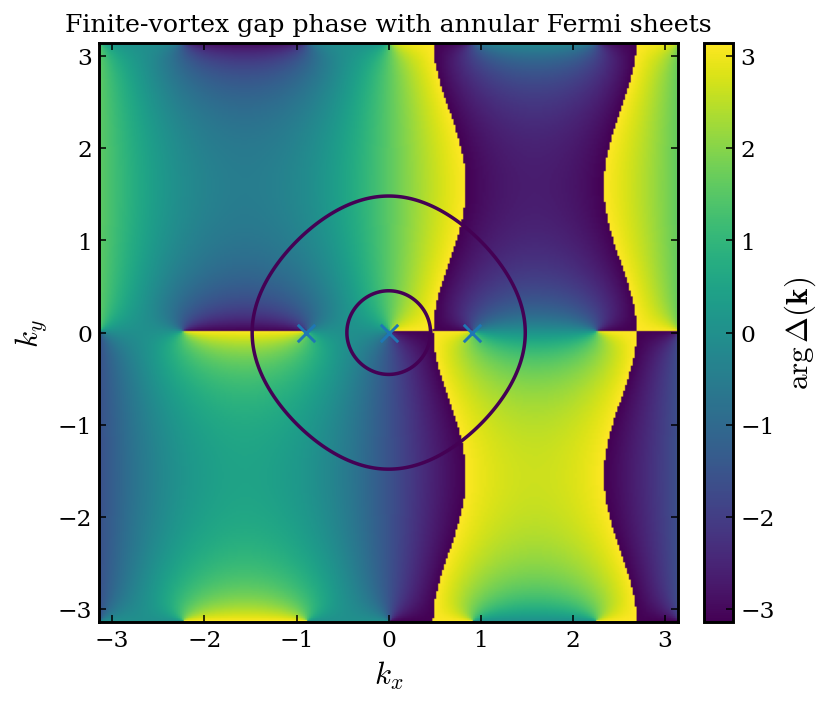

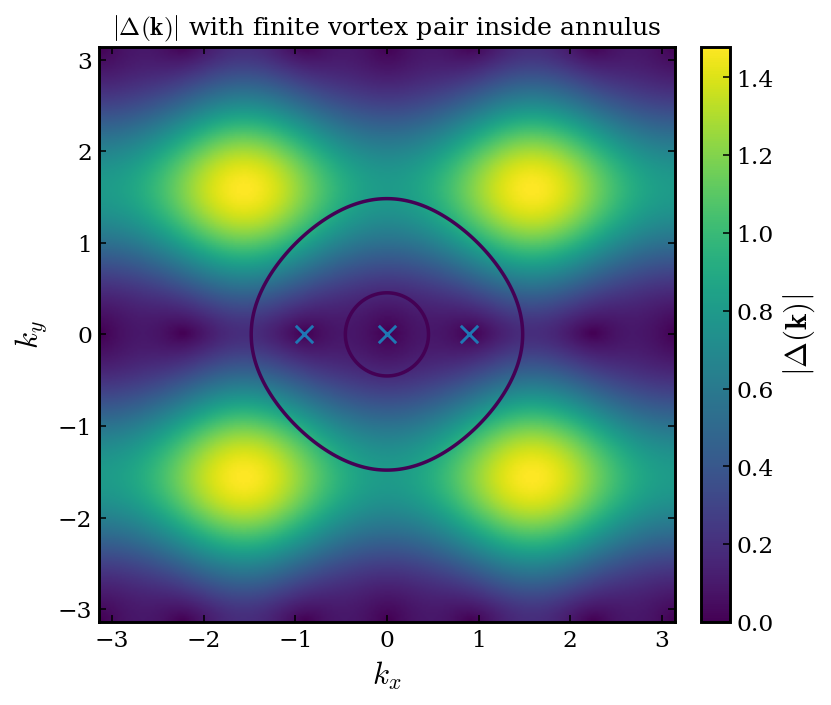

In [5]:
def grid_fields(N=301, fs="annular", pairing="finite_vortices", params=None):
    p = dict(PARAMS if params is None else params)
    ks = np.linspace(-np.pi, np.pi, N, endpoint=False)
    KX, KY = np.meshgrid(ks, ks, indexing="ij")
    XI = xi_k(KX, KY, fs=fs, r_in=p["r_in"], r_out=p["r_out"])
    DEL = delta_k(KX, KY, pairing=pairing, q=p["q"],
                  Delta0=p["Delta0"], chirality=p["chirality"])
    return ks, KX, KY, XI, DEL


ks, KX, KY, XI, DEL = grid_fields(N=301)

for field, label, title, fname in [
    (np.angle(DEL), r"$\arg\Delta(\mathbf{k})$",
     "Finite-vortex gap phase with annular Fermi sheets",
     "annular_finite_vortex_phase.pdf"),
    (np.abs(DEL), r"$|\Delta(\mathbf{k})|$",
     r"$|\Delta(\mathbf{k})|$ with finite vortex pair inside annulus",
     "annular_finite_vortex_magnitude.pdf"),
]:
    fig, ax = plt.subplots(figsize=(6.0, 5.2))
    img = ax.imshow(field.T, origin="lower",
                    extent=[-np.pi, np.pi, -np.pi, np.pi], aspect="equal")
    ax.contour(KX, KY, XI, levels=[0.0], linewidths=1.8)
    ax.scatter([0, PARAMS["q"], -PARAMS["q"]], [0, 0, 0], marker="x", s=80)
    ax.set_title(title)
    ax.set_xlabel(r"$k_x$"); ax.set_ylabel(r"$k_y$")
    cb = fig.colorbar(img, ax=ax, fraction=0.046, pad=0.04)
    cb.set_label(label)
    fig.tight_layout()
    fig.savefig(FIGDIR / fname)
    plt.show()

## 4. Converged vortex-crossing scan (manuscript Fig. 5)

Move the finite-momentum vortex pair radially. The even Chern number
switches on only while the pair lies inside the occupied annulus,
$r_{\rm in} < 2\sin(q/2) < r_{\rm out}$.

Two numerical points, both stated in the manuscript:

1. Sampling is **refined either side of each crossing** but never lands on
   it: at $r = r_{\rm in}$ or $r_{\rm out}$ the gap closes and $C_{\rm BdG}$
   is undefined by construction.
2. The minimum gap is taken from the dedicated $k_y = 0$ scan, not from the
   2D grid, for the reason documented in `min_gap_ky0`.

In [6]:
q_in  = 2*np.arcsin(PARAMS["r_in"]/2)
q_out = 2*np.arcsin(PARAMS["r_out"]/2)
offsets = np.concatenate([-np.linspace(0.02, 0.09, 6)[::-1],
                           np.linspace(0.02, 0.09, 6)])
q_values = np.unique(np.concatenate([np.linspace(0.10, 1.55, 30),
                                     q_in + offsets, q_out + offsets]))

rows = []
for q in q_values:
    p = dict(PARAMS, q=float(q))
    C, mf, _ = fhs_chern(NK_MAIN, fs="annular", pairing="finite_vortices", params=p)
    rows.append(dict(q=float(q), radius=float(2*np.sin(q/2)), C_FHS=C,
                     C_integer=int(round(C)),
                     Q_analytic=analytic_vortex_charge(
                         fs="annular", pairing="finite_vortices", **p),
                     integer_error=abs(C - round(C)),
                     max_plaquette_flux=mf,
                     min_gap=min_gap_ky0(float(q))))

scan = pd.DataFrame(rows)
scan.to_csv(OUTDIR / "annular_vortex_crossing_scan_converged.csv", index=False)

mism = int((scan.C_integer != scan.Q_analytic).sum())
print(f"scan points                      : {len(scan)}   (Nk = {NK_MAIN})")
print(f"points where C_FHS != Q_analytic : {mism}")
print(f"max |C_FHS - Q_analytic|         : {(scan.C_FHS-scan.Q_analytic).abs().max():.2e}")
print(f"max |F_plaq|                     : {scan.max_plaquette_flux.max():.4f}  (< pi)")
i_in  = (scan.radius - PARAMS['r_in']).abs().idxmin()
i_out = (scan.radius - PARAMS['r_out']).abs().idxmin()
i_mid = (scan.radius - 0.87).abs().idxmin()
print(f"min gap at inner crossing        : {scan.min_gap[i_in]:.2e}")
print(f"min gap at outer crossing        : {scan.min_gap[i_out]:.2e}")
print(f"min gap mid-plateau (r ~ 0.87)   : {scan.min_gap[i_mid]:.3e}")
assert mism == 0 and scan.max_plaquette_flux.max() < np.pi

scan points                      : 54   (Nk = 201)
points where C_FHS != Q_analytic : 0
max |C_FHS - Q_analytic|         : 6.66e-16
max |F_plaq|                     : 2.8597  (< pi)
min gap at inner crossing        : 6.64e-04
min gap at outer crossing        : 1.43e-03
min gap mid-plateau (r ~ 0.87)   : 9.237e-02


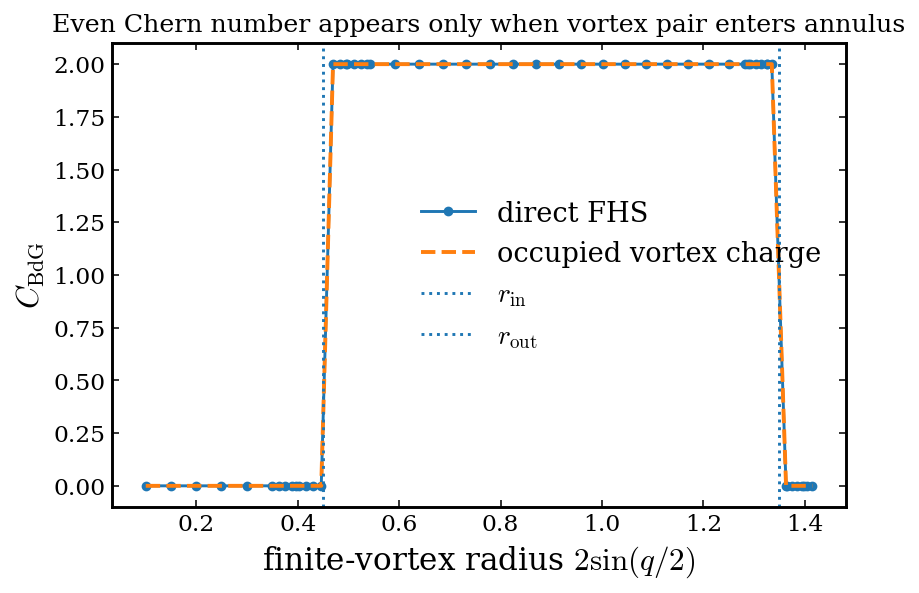

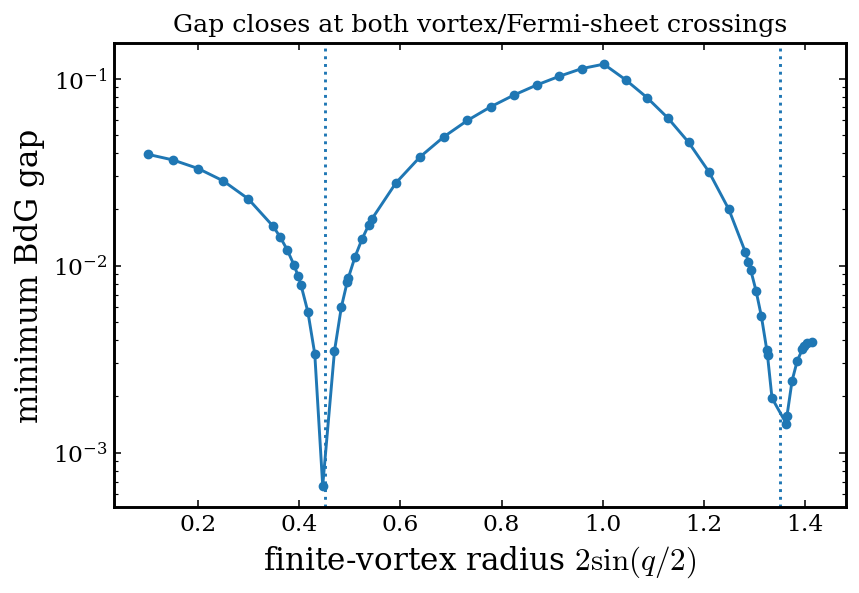

In [7]:
fig, ax = plt.subplots(figsize=(6.3, 4.4))
ax.plot(scan.radius, scan.C_FHS, marker="o", ms=4, label="direct FHS")
ax.plot(scan.radius, scan.Q_analytic, ls="--", lw=2, label="occupied vortex charge")
ax.axvline(PARAMS["r_in"],  ls=":", label=r"$r_{\rm in}$")
ax.axvline(PARAMS["r_out"], ls=":", label=r"$r_{\rm out}$")
ax.set_xlabel(r"finite-vortex radius $2\sin(q/2)$")
ax.set_ylabel(r"$C_{\rm BdG}$")
ax.set_title("Even Chern number appears only when vortex pair enters annulus")
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig(FIGDIR / "annular_vortex_crossing_Chern_scan.pdf")
plt.show()

fig, ax = plt.subplots(figsize=(6.3, 4.4))
ax.semilogy(scan.radius, scan.min_gap, marker="o", ms=4)
ax.axvline(PARAMS["r_in"], ls=":"); ax.axvline(PARAMS["r_out"], ls=":")
ax.set_xlabel(r"finite-vortex radius $2\sin(q/2)$")
ax.set_ylabel("minimum BdG gap")
ax.set_title("Gap closes at both vortex/Fermi-sheet crossings")
fig.tight_layout()
fig.savefig(FIGDIR / "annular_vortex_crossing_gap_scan.pdf")
plt.show()

## 5. FHS grid convergence

Within roughly $0.005$ in radius of either critical value, the gap drops
below the resolution of any practical $k$-grid and
$\max|F_{\rm plaq}| \to \pi$, at which point the discretized invariant is
no longer defined. A coarse $N_k = 81$ scan misassigns $C_{\rm BdG} = 2$ at
one such point; the misassignment disappears for $N_k \geq 121$.

This is why the manuscript reports $\max|F_{\rm plaq}|$ with every Chern
number, and why the production grid is $N_k = 201$.

In [8]:
q_bad = 0.45     # radius 0.4462, just inside r_in = 0.45
print(f"q = {q_bad}  ->  radius = {2*np.sin(q_bad/2):.4f}   "
      f"(r_in = {PARAMS['r_in']}, so Q_analytic = 0)")
print(f"true min gap here: {min_gap_ky0(q_bad):.3e}\n")
conv = []
for Nk in [81, 121, 201, 301, 401, 601]:
    C, mf, _ = fhs_chern(Nk, fs="annular", pairing="finite_vortices",
                         params=dict(PARAMS, q=q_bad))
    conv.append(dict(Nk=Nk, C_FHS=C, C_integer=int(round(C)),
                     max_plaquette_flux=mf))
conv = pd.DataFrame(conv)
conv.to_csv(OUTDIR / "fhs_grid_convergence.csv", index=False)
display(conv)
assert conv.set_index("Nk").loc[81, "C_integer"] == 2      # the artefact
assert (conv[conv.Nk >= 121].C_integer == 0).all()         # converged
print("\nNk = 81 misassigns; Nk >= 121 agrees with Q_analytic = 0.")

q = 0.45  ->  radius = 0.4462   (r_in = 0.45, so Q_analytic = 0)
true min gap here: 6.645e-04



,Nk,C_FHS,C_integer,max_plaquette_flux
0,81,2.000000e+00,2,3.122009
1,121,-4.064042e-16,0,3.026050
2,201,-5.300924e-17,0,2.161675
3,301,-3.710647e-16,0,2.548224
4,401,-5.300924e-17,0,2.338949
5,601,2.650462e-16,0,1.871854



Nk = 81 misassigns; Nk >= 121 agrees with Q_analytic = 0.


## 6. Nambu prefactor: reconciliation with Zeng, Wang and Niu

Zeng, Wang and Niu (arXiv:2607.23764) evaluate

$$\kappa_{xy} = \frac{1}{\hbar T}\sum_n\int\!\frac{d^2k}{(2\pi)^2}\,
\Omega^z_n(\mathbf{k})\int_{E_{n,\mathbf{k}}}^{\infty}\!d\epsilon\,
\epsilon^2\frac{\partial f}{\partial\epsilon},$$

normalized by $\kappa_0^{\rm Z} = \pi k_B^2 T/6\hbar = \pi^2k_B^2T/3h$, and
obtain $|\kappa_{xy}|/\kappa_0^{\rm Z} \to |C_{\rm BdG}|$.

We reproduce that below. The apparent factor of two relative to the
manuscript's $\kappa_{xy}/T = C_{\rm BdG}\pi^2k_B^2/6h$ is Nambu
bookkeeping: the sum runs over both bands of a particle-hole-doubled
Hamiltonian, in which every physical excitation appears twice, so the
conductance carried by physical quasiparticles requires the standard
overall factor of $1/2$. With it restored the two agree, and
$c_- = C_{\rm BdG}/2$ is the half-integer measured by Banerjee et al.

Units throughout: $\hbar = k_B = 1$, hence $h = 2\pi$.

In [9]:
def lattice_pip(Nk=301, t=1.0, mu=1.0, D0=0.5):
    '''Square-lattice p+ip: BdG energies, occupied-band Berry curvature,
    Chern number, and the k-space cell size.'''
    ks = np.linspace(-np.pi, np.pi, Nk, endpoint=False)
    KX, KY = np.meshgrid(ks, ks, indexing="ij")
    xi = -2*t*(np.cos(KX) + np.cos(KY)) - mu
    dk = D0*(np.sin(KX) + 1j*np.sin(KY))
    E = np.sqrt(xi**2 + np.abs(dk)**2)
    d = np.stack([dk.real, -dk.imag, xi], axis=-1)
    n = d/np.linalg.norm(d, axis=-1, keepdims=True)
    h = 2*np.pi/Nk
    dnx = (np.roll(n, -1, 0) - np.roll(n, 1, 0))/(2*h)
    dny = (np.roll(n, -1, 1) - np.roll(n, 1, 1))/(2*h)
    Om = 0.5*np.einsum("...i,...i->...", n, np.cross(dnx, dny))   # lower band
    C = Om.sum()*h*h/(2*np.pi)
    return E, Om, C, h


def kappa_over_kappa0_zeng(T, Nk=241, D0=0.5):
    '''Zeng et al. Eq. (TH), i.e. WITHOUT the 1/2 Nambu factor.'''
    E, Om, C, h = lattice_pip(Nk, D0=D0)
    E0 = np.linspace(-E.max() - 1, E.max() + 1, 900)
    I = np.array([np.trapezoid(
        (lambda e: e**2*(-1.0/(4*T*np.cosh(e/(2*T))**2)))(np.linspace(x, x + 60*T, 3000)),
        np.linspace(x, x + 60*T, 3000)) for x in E0])
    cell = h*h/(2*np.pi)**2
    tot = (np.sum(np.interp(-E.ravel(), E0, I)*Om.ravel())*cell
           + np.sum(np.interp(E.ravel(), E0, I)*(-Om.ravel()))*cell)
    return (tot/T)/(np.pi*T/6.0), C


print(f"{'Delta_0':>8} {'T':>6} {'C_BdG':>9} {'|kappa|/kappa_0^Z':>19}")
for D0 in [0.5, 0.8]:
    for T in [0.05, 0.03]:
        r, C = kappa_over_kappa0_zeng(T, D0=D0)
        print(f"{D0:8.2f} {T:6.3f} {C:+9.4f} {abs(r):19.4f}")
print("\n-> reproduces |kappa_xy|/kappa_0^Z = |C_BdG| = 1, an integer.")
print("   With the 1/2 Nambu factor: kappa_xy/T = C_BdG * pi^2 kB^2/(6h), i.e. c_- = C/2.")
print("   Plateau heights quoted by Zeng et al. should be halved before comparison.")

 Delta_0      T     C_BdG   |kappa|/kappa_0^Z
    0.50  0.050   -0.9984              1.0042


    0.50  0.030   -0.9984              0.9981
    0.80  0.050   -0.9993              1.0199


    0.80  0.030   -0.9993              0.9916

-> reproduces |kappa_xy|/kappa_0^Z = |C_BdG| = 1, an integer.
   With the 1/2 Nambu factor: kappa_xy/T = C_BdG * pi^2 kB^2/(6h), i.e. c_- = C/2.
   Plateau heights quoted by Zeng et al. should be halved before comparison.


## 7. Exact finite-temperature thermal kernel (manuscript Eqs. 21-23, Table I)

Evaluating the band Kubo expression for a two-band BdG spectrum
$\pm E_{\mathbf{k}}$ with occupied-band curvature $\Omega_{\mathbf{k}}$
gives, without approximation,

$$\frac{\kappa_{xy}}{T} = \frac{\pi^2k_B^2}{6h}\,C_{\rm BdG}\,
\Bigl\langle \mathcal{G}\!\left(\tfrac{E_{\mathbf{k}}}{2k_BT}\right)\Bigr\rangle_\Omega,$$

with the universal one-variable kernel

$$\mathcal{G}(x) = \frac{12}{\pi^2}\int_0^x u^2\,\mathrm{sech}^2u\,du
= 1 - \frac{12}{\pi^2}\Bigl[x^2(1-\tanh x) + 2x\ln(1+e^{-2x})
- \mathrm{Li}_2(-e^{-2x})\Bigr].$$

Asymptotics:

$$\mathcal{G}(x) \to 1 - \tfrac{12}{\pi^2}(2x^2+2x+1)e^{-2x}
\quad (x\to\infty),
\qquad
\mathcal{G}(x) \to \tfrac{4}{\pi^2}x^3 \quad (x\to 0),$$

against $\tanh x \to 1 - 2e^{-2x}$ and $\tanh x \to x$. The two share the
exponential approach to the quantized plateau, differing only by a
polynomial prefactor, and part company at high temperature where the true
response falls off as the **cube** rather than the first power.

In [10]:
def Li2(z):
    '''Dilogarithm. scipy.special.spence(z) = Li_2(1-z).'''
    return spence(1.0 - z)


def G_kernel(x):
    '''Universal thermal kernel, closed form. G(inf) = 1.'''
    x = np.asarray(x, dtype=float)
    e = np.exp(-2*x)
    return 1 - (12/np.pi**2)*(x*x*(1 - np.tanh(x))
                              + 2*x*np.log1p(e) - Li2(-e))


def G_quadrature(x, n=200001):
    '''Same quantity by direct quadrature, for verification.'''
    u = np.linspace(0.0, x, n)
    return (12/np.pi**2)*np.trapezoid(u**2/np.cosh(u)**2, u)


print("closed form vs direct quadrature")
err = 0.0
for x in [0.05, 0.2, 0.5, 1.0, 2.0, 3.0, 5.0]:
    a, b = float(G_kernel(x)), G_quadrature(x)
    err = max(err, abs(a - b))
    print(f"  x = {x:5.2f}   closed = {a:.12f}   quad = {b:.12f}   diff = {abs(a-b):.2e}")
assert err < 1e-10
print(f"\nmax discrepancy: {err:.2e}\n")

print("asymptotics as x -> 0:  G ~ (4/pi^2) x^3   vs   tanh x ~ x")
for x in [0.02, 0.05, 0.10]:
    print(f"  x = {x:.3f}   G = {float(G_kernel(x)):.6e}   "
          f"4x^3/pi^2 = {4*x**3/np.pi**2:.6e}   tanh x = {np.tanh(x):.6e}")

closed form vs direct quadrature
  x =  0.05   closed = 0.000050584691   quad = 0.000050584691   diff = 2.02e-15
  x =  0.20   closed = 0.003165919700   quad = 0.003165919700   diff = 3.78e-14
  x =  0.50   closed = 0.043876091504   quad = 0.043876091504   diff = 3.83e-13
  x =  1.00   closed = 0.242189260462   quad = 0.242189260463   diff = 5.07e-13
  x =  2.00   closed = 0.714612463723   quad = 0.714612463720   diff = 2.66e-12
  x =  3.00   closed = 0.924813344552   quad = 0.924813344549   diff = 2.68e-12
  x =  5.00   closed = 0.996632957031   quad = 0.996632957031   diff = 4.59e-13

max discrepancy: 2.68e-12

asymptotics as x -> 0:  G ~ (4/pi^2) x^3   vs   tanh x ~ x
  x = 0.020   G = 3.241500e-06   4x^3/pi^2 = 3.242278e-06   tanh x = 1.999733e-02
  x = 0.050   G = 5.058469e-05   4x^3/pi^2 = 5.066059e-05   tanh x = 4.995837e-02
  x = 0.100   G = 4.028646e-04   4x^3/pi^2 = 4.052847e-04   tanh x = 9.966799e-02


### Benchmark: exact kernel vs the tanh envelope

Two settings. A single massive Dirac cone is where the anomaly kernel is
derived; there the curvature is concentrated near the gap edge. A lattice
$p+ip$ superconductor with a normal-state Fermi surface is the setting
relevant to rhombohedral graphene; there the gap minimum lies on a ring.

In [11]:
# (A) Dirac cone: weight k dk Omega(k) with Omega = m/(2(k^2+m^2)^{3/2})
#     -> (m/2) dE/E^2 on E in [m, inf), normalised to 1/2.
def dirac_exact(T, m=1.0):
    num, _ = quad(lambda E: (m/2)/E**2*float(G_kernel(E/(2*T))), m, 600, limit=600)
    return num/0.5

# (B) lattice p+ip with a Fermi surface
E_lat, Om_lat, C_lat, _ = lattice_pip(Nk=401, D0=0.8)
E_lat, Om_lat = E_lat.ravel(), Om_lat.ravel()
GAP_LAT = E_lat.min()

def lattice_exact(T_over_gap):
    x = E_lat/(2*T_over_gap*GAP_LAT)
    return float(np.sum(Om_lat*G_kernel(x))/np.sum(Om_lat))

# effective scale for the Dirac cone: solve tanh(s/2T) = exact
s_dirac = [brentq(lambda s: np.tanh(s/(2*T)) - dirac_exact(T), 1e-4, 80)
           for T in [0.2, 0.3, 0.5, 0.7, 1.0, 1.3]]
S_EFF = float(np.mean(s_dirac))
print(f"Dirac cone: tanh(s/2T) fits the exact kernel with "
      f"s/Delta = {S_EFF:.4f} +- {np.std(s_dirac):.4f}")
print(f"lattice p+ip: min BdG gap = {GAP_LAT:.4f}, C_BdG = {C_lat:+.4f}\n")

tbl = []
for T in [0.10, 0.15, 0.20, 0.30, 0.50, 0.70, 1.00]:
    tbl.append(dict(T_over_Delta=T,
                    dirac_exact=dirac_exact(T),
                    tanh=np.tanh(1/(2*T)),
                    tanh_eff=np.tanh(S_EFF/(2*T)),
                    lattice_exact=lattice_exact(T)))
envelope = pd.DataFrame(tbl).round(4)
envelope.to_csv(OUTDIR / "table1_thermal_envelope.csv", index=False)
display(envelope)

Dirac cone: tanh(s/2T) fits the exact kernel with s/Delta = 0.8374 +- 0.0011
lattice p+ip: min BdG gap = 0.6705, C_BdG = -0.9997



,T_over_Delta,dirac_exact,tanh,tanh_eff,lattice_exact
0,0.10,0.9980,0.9999,0.9995,0.9994
1,0.15,0.9916,0.9975,0.9925,0.9877
2,0.20,0.9697,0.9866,0.9701,0.9473
3,0.30,0.8843,0.9311,0.8844,0.7919
4,0.50,0.6847,0.7616,0.6844,0.4612
5,0.70,0.5362,0.6134,0.5357,0.2592
6,1.00,0.3961,0.4621,0.3958,0.1161


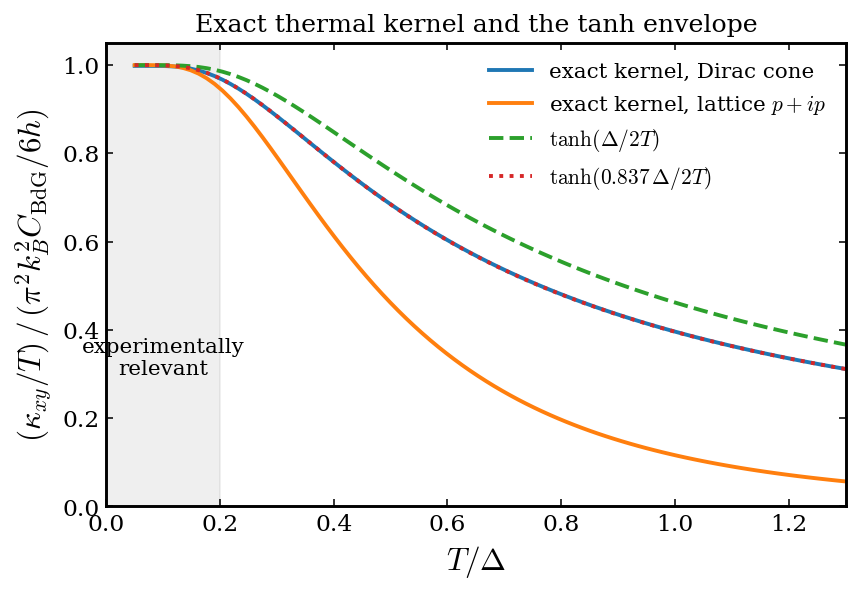

In [12]:
fig, ax = plt.subplots(figsize=(6.3, 4.4))
Ts = np.linspace(0.05, 1.3, 90)
ax.plot(Ts, [dirac_exact(T) for T in Ts], lw=2, label="exact kernel, Dirac cone")
ax.plot(Ts, [lattice_exact(T) for T in Ts], lw=2, label=r"exact kernel, lattice $p+ip$")
ax.plot(Ts, np.tanh(1/(2*Ts)), ls="--", lw=2, label=r"$\tanh(\Delta/2T)$")
ax.plot(Ts, np.tanh(S_EFF/(2*Ts)), ls=":", lw=2,
        label=rf"$\tanh({S_EFF:.3f}\,\Delta/2T)$")
ax.axvspan(0.0, 0.2, alpha=0.12, color="grey")
ax.text(0.10, 0.30, "experimentally\nrelevant", ha="center", fontsize=11)
ax.set_xlabel(r"$T/\Delta$")
ax.set_ylabel(r"$(\kappa_{xy}/T)\,/\,(\pi^2k_B^2 C_{\rm BdG}/6h)$")
ax.set_title("Exact thermal kernel and the tanh envelope")
ax.set_xlim(0, 1.3); ax.set_ylim(0, 1.05)
ax.legend(frameon=False, fontsize=11)
fig.tight_layout()
fig.savefig(FIGDIR / "thermal_envelope_comparison.pdf")
plt.show()

## 8. Summary of artefacts written

In [13]:
print("figures")
for f in sorted(FIGDIR.glob("*.pdf")):
    print("   ", f.name)
print("\ndata")
for f in sorted(OUTDIR.glob("*.csv")):
    print("   ", f.name)

print("\nkey manuscript numbers reproduced above:")
print(f"   Table IV  max integer error      : {benchmarks.integer_error.max():.2e}  (< 1e-14)")
print(f"   Table IV  max |F_plaq|           : {benchmarks.max_plaquette_flux.max():.4f}")
print(f"   Fig. 5    scan mismatches        : {int((scan.C_integer != scan.Q_analytic).sum())}")
print(f"   Fig. 5    max |F_plaq|           : {scan.max_plaquette_flux.max():.4f}")
print(f"   Sec. II D gap at inner crossing  : {scan.min_gap[i_in]:.2e}")
print(f"   Sec. II D gap at outer crossing  : {scan.min_gap[i_out]:.2e}")
print(f"   Table I   Dirac effective scale  : {S_EFF:.3f} Delta")

figures
    annular_finite_vortex_magnitude.pdf
    annular_finite_vortex_phase.pdf
    annular_vortex_crossing_Chern_scan.pdf
    annular_vortex_crossing_gap_scan.pdf
    thermal_envelope_comparison.pdf

data
    annular_vortex_crossing_scan_converged.csv
    fhs_grid_convergence.csv
    table1_thermal_envelope.csv
    table4_four_benchmark_cases.csv

key manuscript numbers reproduced above:
   Table IV  max integer error      : 2.22e-16  (< 1e-14)
   Table IV  max |F_plaq|           : 0.0472
   Fig. 5    scan mismatches        : 0
   Fig. 5    max |F_plaq|           : 2.8597
   Sec. II D gap at inner crossing  : 6.64e-04
   Sec. II D gap at outer crossing  : 1.43e-03
   Table I   Dirac effective scale  : 0.837 Delta
